# Chapter 82: Exhaustible Resources, Biodiversity, and Intergenerational Stewardship

This notebook reruns four worked examples from the chapter: Hotelling arbitrage for a quarry, the extinction margin for a slow-breeding animal, efficiency rebound and backfire, and the quasi-option value of waiting to learn. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def hotelling_required_rent(rent0, r, price1, cost1):
    """Hotelling arbitrage: required next-year rent (1 + r) rent0 against expected rent p1 - c1.

    Principle: hotelling-rule. Book (ch082): rent0 63, r 0.08 gives 68.04 = 99 - 30.96 (no shift);
    r 0.12 gives 70.56 > 68.04 (extract now); c1 36 gives 63 < 68.04 (extract now).
    """
    required = (1 + r) * rent0
    expected = price1 - cost1
    if abs(expected - required) <= 1e-9:
        verdict = "indifferent"
    elif expected > required:
        verdict = "wait"
    else:
        verdict = "now"
    return {"required": required, "expected": expected, "gap": expected - required, "verdict": verdict}


def retention_value(value_next, r, payment=0.0):
    """Present value of keeping a living asset one year: (value next year + payment) / (1 + r).

    Principle: clark-extinction-condition. Book (ch082): 14,700 / 1.07 = 13,738.32; 14,700 / 1.04 = 14,134.62;
    15,600 / 1.07 = 14,579.44.
    """
    return (value_next + payment) / (1 + r)


def rebound(R, e, g):
    """Efficiency rebound: R' = R (1 - e)(1 + g), rho = (1 - e) g / e, backfire when g > e / (1 - e).

    Principle: jevons-demand-expansion-capex. Book (ch082): R 24, e 0.5, g 0.7 gives 20.4 and
    rho 0.70; g 1.3 gives 27.6 and rho 1.30 (backfire).
    """
    eng = R * (1 - e)
    actual = eng * (1 + g)
    return {"engineering": eng, "actual": actual, "rho": (actual - eng) / (e * R), "threshold": e / (1 - e),
            "backfire": actual > R}


def quasi_option_value(now, interim, later, p, high, low):
    """Wait-and-learn value against development now and a fixed commitment to preserve.

    Principle: arrow-fisher-quasi-option-value. V_P = interim + p high + (1 - p) max(later, low);
    fixed = interim + p high + (1 - p) low. Book (ch082): 8 + 0.4(230) + 0.6(120) = 172;
    8 + 0.4(230) + 0.6(50) = 130; develop now 140.
    """
    learn = interim + p * max(high, later) + (1 - p) * max(later, low)
    fixed = interim + p * high + (1 - p) * low
    return {"learn": learn, "fixed": fixed, "now": now, "advantage": learn - now, "qov": learn - fixed}


plt.rcParams.update(HOUSE_RC)


finance = SimpleNamespace(hotelling_required_rent=hotelling_required_rent)


public = SimpleNamespace(retention_value=retention_value, rebound=rebound)


information = SimpleNamespace(quasi_option_value=quasi_option_value)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'hotelling-rule': {'rent0_initial': 60,
                    'r': 0.08,
                    'lambda1_required': 64.8,
                    'price1': 99,
                    'cost1_initial': 27,
                    'rent1_initial': 72,
                    'underground_return': 0.2,
                    'rent0': 63,
                    'rent1': 68.04,
                    'cost1': 30.96,
                    'r_high': 0.12,
                    'required_high': 70.56,
                    'cost1_high': 36,
                    'rent1_high_cost': 63},
 'clark-extinction-condition': {'sale': 14000,
                                'retained': 14700,
                                'r': 0.07,
                                'pv': 13738.32,
                                'liquidation_gap': 261.68,
                                'r_low': 0.04,
                                'pv_low': 14134.62,
                                'gap_low': 134.62,
                                'payment': 900,
                                'payoff_paid': 15600,
                                'pv_paid': 14579.44,
                                'gap_paid': 579.44},
 'jevons-demand-expansion-capex': {'tasks': 2,
                                   'intensity': 12,
                                   'R': 24,
                                   'e': 0.5,
                                   'engineering': 12,
                                   'g': 0.7,
                                   'R1': 20.4,
                                   'rho': 0.7,
                                   'threshold': 1,
                                   'g_high': 1.3,
                                   'R1_high': 27.6,
                                   'rho_high': 1.3},
 'arrow-fisher-quasi-option-value': {'now': 140,
                                     'interim': 8,
                                     'later': 120,
                                     'p': 0.4,
                                     'high': 230,
                                     'low': 50,
                                     'V_P': 172,
                                     'fixed': 130,
                                     'advantage': 32,
                                     'uninformative': 122},
 'constructed': {'hotelling-rule': {'r': [0.04]},
                 'clark-extinction-condition': {'r': [0.1], 'payment': [450]},
                 'jevons-demand-expansion-capex': {'e': [0.25, 0.75], 'g': [0.3, 2.0]},
                 'arrow-fisher-quasi-option-value': {'p': [0.2, 0.6], 'high': [150, 310]}}}


def bar_values(ax, xs, values, texts, size=10.5):
    """Value label above each bar."""
    for x, v, t in zip(xs, values, texts):
        ax.annotate(t, (x, v), xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=size,
                    color=PALETTE["ink"])


def hotelling_picture(r=0.08, c1=30.96):
    bv = BV["hotelling-rule"]
    rent0, p1 = bv["rent0"], bv["price1"]
    res = finance.hotelling_required_rent(rent0, r, p1, c1)
    req, exp = res["required"], res["expected"]
    fig, ax = new_figure()
    vals = [rent0, req, exp]
    cols = [PALETTE["grey"], PALETTE["navy"], PALETTE["teal"]]
    ax.bar(range(3), vals, color=cols, width=0.6)
    bar_values(ax, range(3), vals, [money(v) for v in vals])
    ax.set_xticks(range(3), ["Rent today", f"Required next year\n(1 + r) x 63", f"Expected next year\n99 - {num(c1)}"])
    ax.set_ylim(0, 88)
    ax.set_xlim(-0.6, 2.6)
    ax.set_xlabel("Scarcity rent per tonne")
    ax.set_ylabel("Dollars per tonne")
    if res["verdict"] == "indifferent":
        verdict, short = "the two returns are equal and no marginal shift is profitable", "No profitable shift"
    elif res["verdict"] == "wait":
        verdict = (f"expected rent beats the required {money(req)} by {money(exp - req)}, so the owner postpones "
                   f"extraction")
        short = "Postpone extraction"
    else:
        verdict = (f"expected rent falls short of the required {money(req)} by {money(req - exp)}, so the owner "
                   f"moves extraction toward the present")
        short = "Extract more now"
    label(ax, 2.55, 80, short, col="terracotta", dx=0, dy=0, ha="right", va="center")
    ret = exp / rent0 - 1
    metrics = {"Required next-year rent": money(req), "Expected next-year rent": money(exp),
               "Underground return": f"{num(100 * ret, 1)}%", "Required return": f"{num(100 * r, 0)}%",
               "Decision": short}
    steps = [f"Required rent = (1 + {num(r)}) x 63 = {num(1 + r)} x 63 = {num(req)}",
             f"Expected rent = 99 - {num(c1)} = {num(exp)}",
             f"Underground return = {num(exp)} / 63 - 1 = {num(100 * ret, 1)}%",
             f"Compare: {num(exp)} {'=' if res['verdict'] == 'indifferent' else ('>' if exp > req else '<')} {num(req)}"]
    interp = (f"A unit left in the ground must earn {num(100 * r, 0)}% to match the financial return: "
              f"{num(1 + r)} x 63 = {num(req)}. Next year's expected rent is 99 - {num(c1)} = {num(exp)}: "
              f"{verdict}.")
    alt = (f"Bars for today's rent $63, the required next-year rent {money(req)} at {num(100 * r, 0)}% and the "
           f"expected next-year rent {money(exp)} with cost {money(c1)}. Decision: {short.lower()}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def clark_picture(r=0.07, s=0):
    bv = BV["clark-extinction-condition"]
    sale, kept = bv["sale"], bv["retained"]
    rates = [0.04, 0.07, 0.10]
    pvs = [public.retention_value(kept, x, s) for x in rates]
    pv = public.retention_value(kept, r, s)
    gap = pv - sale
    fig, ax = new_figure()
    cols = [PALETTE["teal"] if abs(x - r) < 1e-12 else PALETTE["grey"] for x in rates]
    ax.bar(range(3), pvs, color=cols, width=0.6)
    bar_values(ax, range(3), pvs, [money(v) for v in pvs])
    hline(ax, sale, col="terracotta")
    ax.text(0.02, 0.97, tex_safe("red line: sell today for $14,000"), transform=ax.transAxes, ha="left", va="top",
            fontsize=10.5, color=PALETTE["terracotta"])
    ax.set_xticks(range(3), [f"r = {num(100 * x, 0)}%" for x in rates])
    ax.set_ylim(12_000, 16_300)
    ax.set_xlim(-0.6, 2.6)
    ax.set_xlabel("Owner's discount rate")
    ax.set_ylabel("Present value of keeping the animal ($)")
    keep = gap > 0
    pay = f" + {money(s, 0)}" if s else ""
    metrics = {"Payoff next year": money(kept + s, 0), "PV of retention": money(pv),
               "Sale value today": money(sale, 0),
               "Margin": f"{'retention' if keep else 'liquidation'} by {money(abs(gap))}",
               "Decision": "Keep the animal" if keep else "Sell now"}
    steps = ([f"Payoff next year = $14,700{pay} = {money(kept + s, 0)}"] if s else []) + [
             f"PV = {num(kept + s, 0)} / {num(1 + r)} = {num(pv)}",
             f"{num(pv)} - 14,000 = {num(gap)}"]
    if keep:
        tail = f"Keeping the animal beats selling by {money(gap)}."
    else:
        tail = (f"Selling now wins by {money(-gap)}; if this holds for every animal that can be caught, the private "
                f"program tends toward extinction.")
    interp = (f"Retention pays {money(kept + s, 0)} next year" + (f", including a {money(s, 0)} survival payment" if s
                                                                 else "") +
              f". Discounted at {num(100 * r, 0)}%: {num(kept + s, 0)} / {num(1 + r)} = {num(pv)}, against a sale "
              f"value of 14,000. {tail}")
    alt = (f"Bars of the present value of keeping the animal at 4, 7 and 10 percent with a survival payment of "
           f"{money(s, 0)}, against a line at the $14,000 sale value. At {num(100 * r, 0)}% the value is {money(pv)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def rebound_picture(e=0.50, g=0.7):
    R = BV["jevons-demand-expansion-capex"]["R"]
    res = public.rebound(R, e, g)
    eng, act, rho, thr = res["engineering"], res["actual"], res["rho"], res["threshold"]
    fig, ax = new_figure()
    vals = [R, eng, act]
    cols = [PALETTE["grey"], PALETTE["gold"], PALETTE["terracotta"] if res["backfire"] else PALETTE["teal"]]
    ax.bar(range(3), vals, color=cols, width=0.6)
    bar_values(ax, range(3), vals, [num(v, 1) for v in vals])
    hline(ax, R, col="grey")
    ax.set_xticks(range(3), ["Baseline R", "Engineering R(1 - e)", "Actual R'"])
    ax.set_ylim(0, max(vals) * 1.22)
    ax.set_xlim(-0.6, 2.6)
    ax.set_xlabel("Resource use")
    ax.set_ylabel("Million kilowatt-hours per month")
    back = res["backfire"]
    metrics = {"Engineering use R(1 - e)": num(eng, 1), "Actual use R'": num(act, 1), "Rebound rho": num(rho, 2),
               "Backfire threshold g >": num(thr, 3 if thr < 1 and round(thr, 2) != thr else 2),
               "Backfire": "yes" if back else "no"}
    thr_txt = metrics["Backfire threshold g >"]
    steps = [f"R(1 - e) = 24 x {num(1 - e)} = {num(eng, 1)}",
             f"R' = 24 x {num(1 - e)} x {num(1 + g)} = {num(act, 1)}",
             f"rho = {num(1 - e)} x {num(g)} / {num(e)} = {num(rho, 2)}",
             f"Threshold e / (1 - e) = {num(e)} / {num(1 - e)} = {thr_txt}"]
    if back:
        tail = (f"Growth {num(g)} exceeds the threshold {thr_txt}, so use ends {num(act - R, 1)} million above the "
                f"baseline: backfire.")
    else:
        tail = (f"Growth {num(g)} is below the threshold {thr_txt}, so use stays {num(R - act, 1)} million below the "
                f"baseline and part of the saving survives.")
    interp = (f"Cutting intensity by {num(100 * e, 0)}% would bring use to 24 x {num(1 - e)} = {num(eng, 1)} million "
              f"kWh, but tasks grow {num(100 * g, 0)}%, so use is {num(eng, 1)} x {num(1 + g)} = {num(act, 1)}. "
              f"Rebound is {num(1 - e)} x {num(g)} / {num(e)} = {num(rho, 2)}, or {num(100 * rho, 0)}% of the "
              f"engineering saving. {tail}")
    alt = (f"Bars of baseline use 24, engineering use {num(eng, 1)} and actual use {num(act, 1)} million kilowatt-hours "
           f"for an intensity cut of {num(100 * e, 0)}% and task growth of {num(100 * g, 0)}%.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def option_picture(p=0.4, high=230):
    bv = BV["arrow-fisher-quasi-option-value"]
    now, interim, later, low = bv["now"], bv["interim"], bv["later"], bv["low"]
    res = information.quasi_option_value(now, interim, later, p, high, low)
    learn, fixed = res["learn"], res["fixed"]
    fig, ax = new_figure()
    vals = [now, learn, fixed]
    best = max(vals)
    cols = [PALETTE["teal"] if abs(v - best) < 1e-9 else PALETTE["grey"] for v in vals]
    ax.bar(range(3), vals, color=cols, width=0.6)
    bar_values(ax, range(3), vals, [num(v, 0) for v in vals])
    ax.set_xticks(range(3), ["Develop now", "Wait and learn V_P", "Wait, then preserve"])
    ax.set_ylim(0, 275)
    ax.set_xlim(-0.6, 2.6)
    ax.set_xlabel("Choice")
    ax.set_ylabel("Present value ($ million)")
    q = 1 - p
    win_names = [n for n, v in zip(["develop now", "wait and learn", "wait, then preserve"], vals)
                 if abs(v - best) < 1e-9]
    metrics = {"Wait and learn V_P": num(learn, 0), "Wait, then preserve": num(fixed, 0), "Develop now": num(now, 0),
               "Waiting minus developing now": num(learn - now, 0), "Best choice": (" and ".join(win_names) + " tie") if len(win_names) > 1 else win_names[0]}
    steps = [f"V_P = 8 + {num(p, 1)}({num(high, 0)}) + {num(q, 1)}(120) = {num(learn, 0)}",
             f"Preserve = 8 + {num(p, 1)}({num(high, 0)}) + {num(q, 1)}(50) = {num(fixed, 0)}",
             f"V_P - develop now = {num(learn, 0)} - 140 = {num(learn - now, 0)}"]
    if abs(learn - now) < 1e-9:
        cmp = "Waiting to learn and developing now tie"
    elif learn > now:
        cmp = f"Waiting to learn beats developing now by {num(learn - now, 0)} million"
    elif learn < now:
        cmp = f"Developing now beats waiting to learn by {num(now - learn, 0)} million"
    pres = ("even committing to preserve beats developing now" if fixed > now + 1e-9
            else "committing to preserve after waiting would not beat developing now")
    interp = (f"Waiting keeps both options: 8 + {num(p, 1)} x {num(high, 0)} + {num(q, 1)} x 120 = {num(learn, 0)} "
              f"million. A fixed commitment to preserve gives 8 + {num(p, 1)} x {num(high, 0)} + {num(q, 1)} x 50 = "
              f"{num(fixed, 0)}. {cmp}; {pres}. The gap of {num(learn - fixed, 0)} between the two waiting values "
              f"is the value of being able to develop in the low state.")
    alt = (f"Bars for developing now (140), waiting and learning ({num(learn, 0)}) and waiting then preserving "
           f"({num(fixed, 0)}), in $ million, with high-state probability {num(p, 1)} and high-state value "
           f"{num(high, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Hotelling rule: extract now or wait

Scarcity rent is price minus marginal extraction cost, $$\lambda_t=p_t-c_t$$ and on an efficient path $$\lambda_{t+1}=(1+r)\lambda_t.$$ With today's rent at \$60 and an 8 percent return, $$\lambda_1=1.08(60)=\$64.80.$$ After the market adjusts, today's rent is \$63 and next year's price \$99 less cost \$30.96 gives $68.04=1.08(63)$.

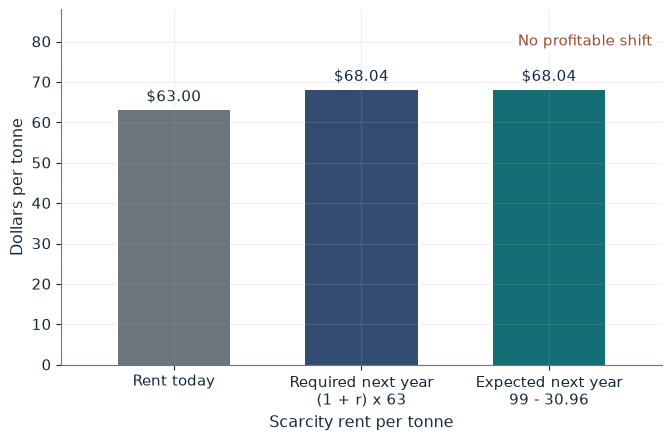

Required next-year rent  $68.04
Expected next-year rent  $68.04
Underground return       8.0%
Required return          8%
Decision                 No profitable shift

Worked steps:
  1. Required rent = (1 + 0.08) x 63 = 1.08 x 63 = 68.04
  2. Expected rent = 99 - 30.96 = 68.04
  3. Underground return = 68.04 / 63 - 1 = 8.0%
  4. Compare: 68.04 = 68.04

A unit left in the ground must earn 8% to match the financial return: 1.08 x 63 = 68.04. Next year's expected rent is 99 - 30.96 = 68.04: the two returns are equal and no marginal shift is profitable.


In [2]:
show(hotelling_picture(r=0.08, c1=30.96))

Change one input, `r`, and hold the others at the book's values:

In [3]:
sweep(hotelling_picture, 'r', [0.04, 0.08, 0.12], {'c1': 30.96}, ['Required next-year rent', 'Expected next-year rent', 'Decision'])

r | Required next-year rent | Expected next-year rent | Decision
0.04 | $65.52 | $68.04 | Postpone extraction
0.08 | $68.04 | $68.04 | No profitable shift
0.12 | $70.56 | $68.04 | Extract more now


At 8 percent the returns are equal and no shift pays. At 12 percent the required rent is \$70.56, above \$68.04, so extraction moves toward the present. A next-year cost of \$36 (`c1=36`) leaves rent at \$63, so waiting gains nothing.

## 2. Clark extinction condition: sell or keep the animal

Selling today yields \$14,000; keeping the animal yields \$14,700 next year.

$$PV_K=\frac{14{,}700}{1.07}=\$13{,}738.32.$$

At a 4 percent rate, $$\frac{14{,}700}{1.04}=\$14{,}134.62,$$

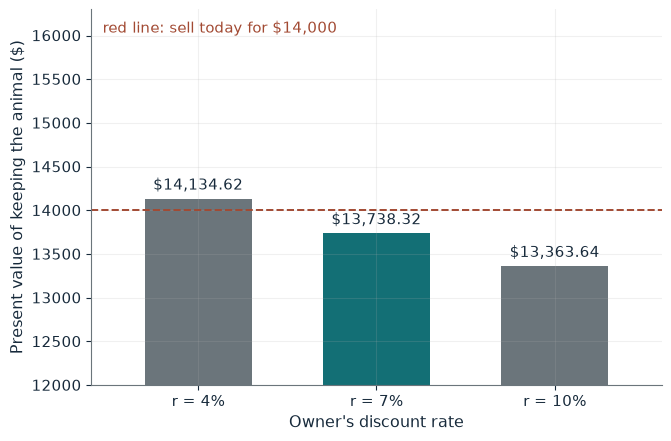

Payoff next year  $14,700
PV of retention   $13,738.32
Sale value today  $14,000
Margin            liquidation by $261.68
Decision          Sell now

Worked steps:
  1. PV = 14,700 / 1.07 = 13,738.32
  2. 13,738.32 - 14,000 = -261.68

Retention pays $14,700 next year. Discounted at 7%: 14,700 / 1.07 = 13,738.32, against a sale value of 14,000. Selling now wins by $261.68; if this holds for every animal that can be caught, the private program tends toward extinction.


In [4]:
show(clark_picture(r=0.07, s=0))

Change one input, `s`, and hold the others at the book's values:

In [5]:
sweep(clark_picture, 's', [0, 450, 900], {'r': 0.07}, ['PV of retention', 'Margin', 'Decision'])

s | PV of retention | Margin | Decision
0 | $13,738.32 | liquidation by $261.68 | Sell now
450 | $14,158.88 | retention by $158.88 | Keep the animal
900 | $14,579.44 | retention by $579.44 | Keep the animal


At 7 percent selling wins by \$261.68. A \$900 payment per surviving adult raises the payoff to \$15,600, worth \$14,579.44 today, so keeping the animal wins by \$579.44.

## 3. Jevons-like demand expansion: efficiency rebound and backfire

$$R'=R(1-e)(1+g).$$

$$\rho=\frac{R'-R(1-e)}{eR}=\frac{(1-e)g}{e}.$$

$$(1-e)(1+g)>1,\qquad g>\frac{e}{1-e}.$$

With 24 million kWh, a 50 percent cut and 70 percent task growth, $$R'=3.4(6)=20.4\text{ million kilowatt-hours}.$$

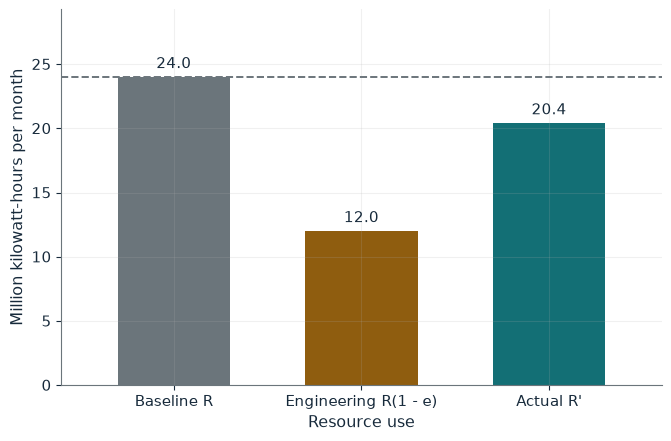

Engineering use R(1 - e)  12.0
Actual use R'             20.4
Rebound rho               0.70
Backfire threshold g >    1.00
Backfire                  no

Worked steps:
  1. R(1 - e) = 24 x 0.50 = 12.0
  2. R' = 24 x 0.50 x 1.70 = 20.4
  3. rho = 0.50 x 0.70 / 0.50 = 0.70
  4. Threshold e / (1 - e) = 0.50 / 0.50 = 1.00

Cutting intensity by 50% would bring use to 24 x 0.50 = 12.0 million kWh, but tasks grow 70%, so use is 12.0 x 1.70 = 20.4. Rebound is 0.50 x 0.70 / 0.50 = 0.70, or 70% of the engineering saving. Growth 0.70 is below the threshold 1.00, so use stays 3.6 million below the baseline and part of the saving survives.


In [6]:
show(rebound_picture(e=0.50, g=0.7))

Change one input, `g`, and hold the others at the book's values:

In [7]:
sweep(rebound_picture, 'g', [0.3, 0.7, 1.3, 2.0], {'e': 0.5}, ["Actual use R'", 'Rebound rho', 'Backfire'])

g | Actual use R' | Rebound rho | Backfire
0.3 | 15.6 | 0.30 | no
0.7 | 20.4 | 0.70 | no
1.3 | 27.6 | 1.30 | yes
2.0 | 36.0 | 2.00 | yes


Rebound is 70 percent: the extra tasks take back most of the 12 million kWh saving but not all of it. At 130 percent growth use reaches 27.6, above the baseline 24: backfire.

## 4. Arrow-Fisher quasi-option value: wait to learn

Developing now is worth 140 ($ million). Waiting preserves 8 of services and lets the decision follow a study: preserve if the estuary is worth 230 (probability 0.4), develop for 120 otherwise.

$$V_P=8+0.4(230)+0.6(120)=\$172\text{ million}.$$

Committing to preserve regardless gives $$8+0.4(230)+0.6(50)=\$130\text{ million},$$

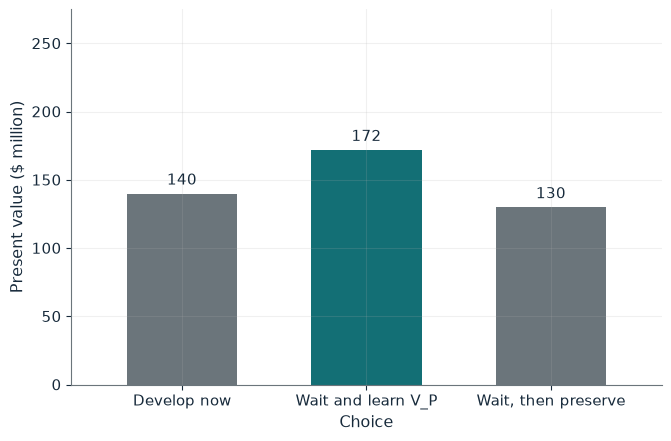

Wait and learn V_P            172
Wait, then preserve           130
Develop now                   140
Waiting minus developing now  32
Best choice                   wait and learn

Worked steps:
  1. V_P = 8 + 0.4(230) + 0.6(120) = 172
  2. Preserve = 8 + 0.4(230) + 0.6(50) = 130
  3. V_P - develop now = 172 - 140 = 32

Waiting keeps both options: 8 + 0.4 x 230 + 0.6 x 120 = 172 million. A fixed commitment to preserve gives 8 + 0.4 x 230 + 0.6 x 50 = 130. Waiting to learn beats developing now by 32 million; committing to preserve after waiting would not beat developing now. The gap of 42 between the two waiting values is the value of being able to develop in the low state.


In [8]:
show(option_picture(p=0.4, high=230))

Change one input, `p`, and hold the others at the book's values:

In [9]:
sweep(option_picture, 'p', [0.2, 0.4, 0.6], {'high': 230}, ['Wait and learn V_P', 'Wait, then preserve', 'Best choice'])

p | Wait and learn V_P | Wait, then preserve | Best choice
0.2 | 150 | 94 | wait and learn
0.4 | 172 | 130 | wait and learn
0.6 | 194 | 166 | wait and learn


Waiting beats developing now by 32, while a fixed commitment to preserve (130) would lose to development. The flexibility to develop in the low state, not preservation itself, makes waiting worthwhile.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

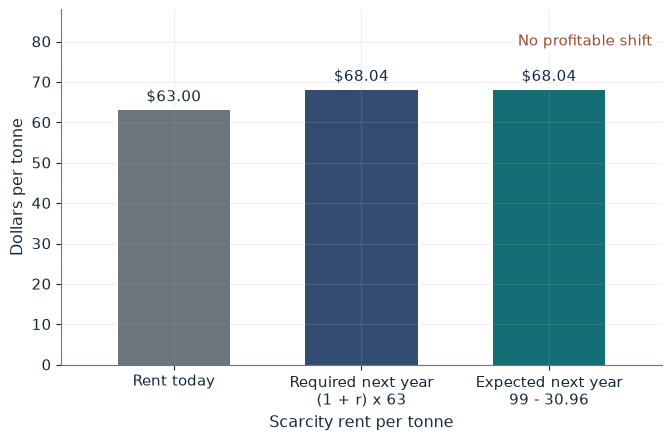

Required next-year rent  $68.04
Expected next-year rent  $68.04
Underground return       8.0%
Required return          8%
Decision                 No profitable shift

Worked steps:
  1. Required rent = (1 + 0.08) x 63 = 1.08 x 63 = 68.04
  2. Expected rent = 99 - 30.96 = 68.04
  3. Underground return = 68.04 / 63 - 1 = 8.0%
  4. Compare: 68.04 = 68.04

A unit left in the ground must earn 8% to match the financial return: 1.08 x 63 = 68.04. Next year's expected rent is 99 - 30.96 = 68.04: the two returns are equal and no marginal shift is profitable.


In [10]:
show(hotelling_picture(r=0.08, c1=30.96))

## Practice

**1.** At r = 0.04 and next-year cost \$36, which is larger, the required or the expected next-year rent?

<details><summary>Answer</summary>

Required 1.04 x 63 = 65.52; expected 99 - 36 = 63; 63 < 65.52, so extraction shifts to the present.

</details>

**2.** At r = 0.10 and a \$900 survival payment, does keeping the animal win?

<details><summary>Answer</summary>

15,600 / 1.10 = 14,181.82, which beats 14,000 by 181.82: yes.

</details>

**3.** At e = 0.25 and g = 0.7, what are R' and the rebound?

<details><summary>Answer</summary>

R' = 24 x 0.75 x 1.7 = 30.6 million kWh, above 24 (backfire); rho = 0.75 x 0.7 / 0.25 = 2.10.

</details>